# Diabetes Prediction
End-to-end ML workflow: data loading → exploration → EDA → preprocessing → feature engineering → **data visualization** → model training → model evaluation.

**Target:** `Outcome` (1 = diabetic, 0 = not diabetic). Place `Diabetes.csv` next to this notebook or edit `DATA_PATH`.

## 0. Setup

In [8]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
RANDOM_STATE = 42
DATA_PATH = "Diabetes.csv"   # change if the file is elsewhere
PALETTE = {0: "#4C72B0", 1: "#DD8452"}

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data Loading

In [10]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Diabetes.csv")
print("Shape:", df.shape)
df.head()

Shape: (2768, 10)


,Id,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,6,148,72,35,0,33.6,0.627,50,1
1,2,1,85,66,29,0,26.6,0.351,31,0
2,3,8,183,64,0,0,23.3,0.672,32,1
3,4,1,89,66,23,94,28.1,0.167,21,0
4,5,0,137,40,35,168,43.1,2.288,33,1


## 2. Data Exploration

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2768 entries, 0 to 2767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        2768 non-null   int64  
 1   Pregnancies               2768 non-null   int64  
 2   Glucose                   2768 non-null   int64  
 3   BloodPressure             2768 non-null   int64  
 4   SkinThickness             2768 non-null   int64  
 5   Insulin                   2768 non-null   int64  
 6   BMI                       2768 non-null   float64
 7   DiabetesPedigreeFunction  2768 non-null   float64
 8   Age                       2768 non-null   int64  
 9   Outcome                   2768 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 216.4 KB


In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,2768.0,1384.500000,799.197097,1.000,692.750,1384.500,2076.250,2768.00
Pregnancies,2768.0,3.742775,3.323801,0.000,1.000,3.000,6.000,17.00
Glucose,2768.0,121.102601,32.036508,0.000,99.000,117.000,141.000,199.00
BloodPressure,2768.0,69.134393,19.231438,0.000,62.000,72.000,80.000,122.00
SkinThickness,2768.0,20.824422,16.059596,0.000,0.000,23.000,32.000,110.00
Insulin,2768.0,80.127890,112.301933,0.000,0.000,37.000,130.000,846.00
BMI,2768.0,32.137392,8.076127,0.000,27.300,32.200,36.625,80.60
DiabetesPedigreeFunction,2768.0,0.471193,0.325669,0.078,0.244,0.375,0.624,2.42
Age,2768.0,33.132225,11.777230,21.000,24.000,29.000,40.000,81.00
Outcome,2768.0,0.343931,0.475104,0.000,0.000,0.000,1.000,1.00


In [13]:
print("Null values:", int(df.isna().sum().sum()))
print("\nTarget balance:")
print(df.Outcome.value_counts(), "\n")
print(df.Outcome.value_counts(normalize=True).round(3))

Null values: 0

Target balance:
Outcome
0    1816
1     952
Name: count, dtype: int64 

Outcome
0    0.656
1    0.344
Name: proportion, dtype: float64


### Hidden data-quality problems
Two issues are not visible from `isna()`:
1. **Zeros that are really missing values** — a glucose, blood pressure, skin thickness, insulin or BMI of 0 is physiologically impossible.
2. **Duplicate rows** — `Id` makes every row look unique, but the underlying measurements may repeat.

In [14]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zeros = pd.DataFrame({"zeros": (df[zero_cols] == 0).sum(),
                      "pct": ((df[zero_cols] == 0).mean() * 100).round(1)})
display(zeros)

feat_cols = [c for c in df.columns if c not in ("Id", "Outcome")]
dups = df.drop(columns="Id").duplicated().sum()
print(f"\nRows duplicated (ignoring Id): {dups} of {len(df)}  ({dups/len(df):.0%})")
print("Unique rows:", len(df.drop(columns='Id').drop_duplicates()))

,zeros,pct
Glucose,18,0.7
BloodPressure,125,4.5
SkinThickness,800,28.9
Insulin,1330,48.0
BMI,39,1.4



Rows duplicated (ignoring Id): 1990 of 2768  (72%)
Unique rows: 778


**This matters a lot.** If duplicated rows are left in, copies of the same patient land in both the training and test sets, so the model is partly tested on data it has memorised and the scores look far better than they really are. The next cells quantify this.

In [15]:
# Demonstration: what happens if we DON'T remove duplicates
Xr, yr = df[feat_cols], df.Outcome
Xa, Xb, ya, yb = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=RANDOM_STATE)
leaky = RandomForestClassifier(300, random_state=RANDOM_STATE).fit(Xa, ya)
print(f"Random Forest accuracy WITH duplicate leakage: {accuracy_score(yb, leaky.predict(Xb)):.3f}  <- misleadingly high")

Random Forest accuracy WITH duplicate leakage: 0.996  <- misleadingly high


## 3. Exploratory Data Analysis (EDA)

In [16]:
eda = df.copy()
eda[zero_cols] = eda[zero_cols].replace(0, np.nan)        # zeros → NaN (for honest statistics)
eda = eda.drop(columns="Id").drop_duplicates()
print("Unique records:", len(eda))
print(eda.Outcome.value_counts(normalize=True).round(3).to_string())

Unique records: 778
Outcome
0    0.65
1    0.35


In [17]:
print("Mean of each feature by outcome:")
eda.groupby("Outcome").mean().T.round(2)

Mean of each feature by outcome:


Outcome,0,1
Pregnancies,3.28,4.83
Glucose,111.10,142.27
BloodPressure,70.72,75.37
SkinThickness,27.49,33.26
Insulin,131.06,206.72
BMI,31.15,35.41
DiabetesPedigreeFunction,0.43,0.55
Age,31.24,37.27


In [18]:
print("Correlation with Outcome:")
eda.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

Correlation with Outcome:


,Outcome
Glucose,0.486
Insulin,0.302
BMI,0.279
SkinThickness,0.246
Age,0.244
Pregnancies,0.220
BloodPressure,0.178
DiabetesPedigreeFunction,0.172


In [19]:
print("Diabetes rate by age band and BMI band")
age_band = pd.cut(eda.Age, [20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
bmi_band = pd.cut(eda.BMI, [0, 25, 30, 35, 100], labels=["<25", "25-30", "30-35", "35+"])
display(eda.groupby(age_band).Outcome.agg(["mean", "count"]).round(3))
display(eda.groupby(bmi_band).Outcome.agg(["mean", "count"]).round(3))

Diabetes rate by age band and BMI band


,mean,count
Age,,
21-30,0.215,419
31-40,0.475,160
41-50,0.573,117
51+,0.476,82


,mean,count
BMI,,
<25,0.071,113
25-30,0.244,180
30-35,0.455,222
35+,0.464,252


**EDA findings**
- Only ~778 unique patients remain once duplicates are removed (about 35% diabetic).
- `Glucose` is by far the strongest single predictor; `BMI`, `Age`, and `Pregnancies` follow.
- Insulin (~48% zeros) and SkinThickness (~29%) are the most incomplete columns.
- Diabetes rate rises steadily with BMI and age.

## 4. Data Preprocessing

Steps, in an order that avoids leakage:
1. Replace impossible zeros with `NaN`
2. Drop duplicate records and the `Id` column
3. Train/test split (stratified)
4. Impute missing values using **medians computed on the training set only**

In [20]:
clean = df.copy()
clean[zero_cols] = clean[zero_cols].replace(0, np.nan)
clean = clean.drop(columns="Id").drop_duplicates().reset_index(drop=True)
print("Clean shape:", clean.shape)
print("\nMissing values per column:")
print(clean.isna().sum()[lambda s: s > 0])

Clean shape: (778, 9)

Missing values per column:
Glucose            5
BloodPressure     36
SkinThickness    229
Insulin          377
BMI               11
dtype: int64


In [21]:
y = clean.Outcome
X_raw = clean.drop(columns="Outcome")
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train_raw.shape, "| Test:", X_test_raw.shape)
print("Train positive rate:", round(y_train.mean(), 3), "| Test positive rate:", round(y_test.mean(), 3))

Train: (622, 8) | Test: (156, 8)
Train positive rate: 0.349 | Test positive rate: 0.353


In [22]:
medians = X_train_raw[zero_cols].median()      # statistics from TRAIN only
print(medians.round(2).to_string())

Glucose          117.0
BloodPressure     72.0
SkinThickness     30.0
Insulin          125.0
BMI               32.4


## 5. Feature Engineering

In [23]:
def engineer(X_in):
    X = X_in.copy()
    # missing-ness itself can be informative (e.g. insulin not measured)
    X["Insulin_missing"] = X.Insulin.isna().astype(int)
    X["Skin_missing"]    = X.SkinThickness.isna().astype(int)
    # impute with training medians
    X[zero_cols] = X[zero_cols].fillna(medians)
    # new features
    X["Glucose_BMI"]     = X.Glucose * X.BMI / 100
    X["Insulin_log"]     = np.log1p(X.Insulin)
    X["Glucose_Insulin"] = X.Glucose / (X.Insulin + 1)
    X["Age_Glucose"]     = X.Age * X.Glucose / 100
    X["Pregnancy_Rate"]  = X.Pregnancies / (X.Age - 15).clip(lower=1)
    X["Prediabetic_Glu"] = (X.Glucose >= 100).astype(int)
    X["Diabetic_Glu"]    = (X.Glucose >= 126).astype(int)
    X["Obese"]           = (X.BMI >= 30).astype(int)
    X["High_BP"]         = (X.BloodPressure >= 90).astype(int)
    X["Age_30_45"]       = X.Age.between(30, 45).astype(int)
    X["Age_45plus"]      = (X.Age > 45).astype(int)
    return X

X_train = engineer(X_train_raw)
X_test  = engineer(X_test_raw)
print("Feature matrix:", X_train.shape, "| nulls:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
print(list(X_train.columns))

Feature matrix: (622, 21) | nulls: 0
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Insulin_missing', 'Skin_missing', 'Glucose_BMI', 'Insulin_log', 'Glucose_Insulin', 'Age_Glucose', 'Pregnancy_Rate', 'Prediabetic_Glu', 'Diabetic_Glu', 'Obese', 'High_BP', 'Age_30_45', 'Age_45plus']


In [24]:
new_feats = ["Insulin_missing", "Skin_missing", "Glucose_BMI", "Insulin_log", "Glucose_Insulin", "Age_Glucose",
             "Pregnancy_Rate", "Prediabetic_Glu", "Diabetic_Glu", "Obese", "High_BP", "Age_30_45", "Age_45plus"]
pd.concat([X_train[new_feats], y_train], axis=1).corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

,Outcome
Glucose_BMI,0.498
Diabetic_Glu,0.416
Age_Glucose,0.399
Prediabetic_Glu,0.328
Obese,0.287
Insulin_log,0.267
Age_30_45,0.186
Age_45plus,0.122
High_BP,0.086
Pregnancy_Rate,0.041


## 6. Data Visualization

Plots below use the cleaned dataset (zeros → missing, duplicates removed); missing values are simply left out of each plot.

### 6.1 Target and data quality

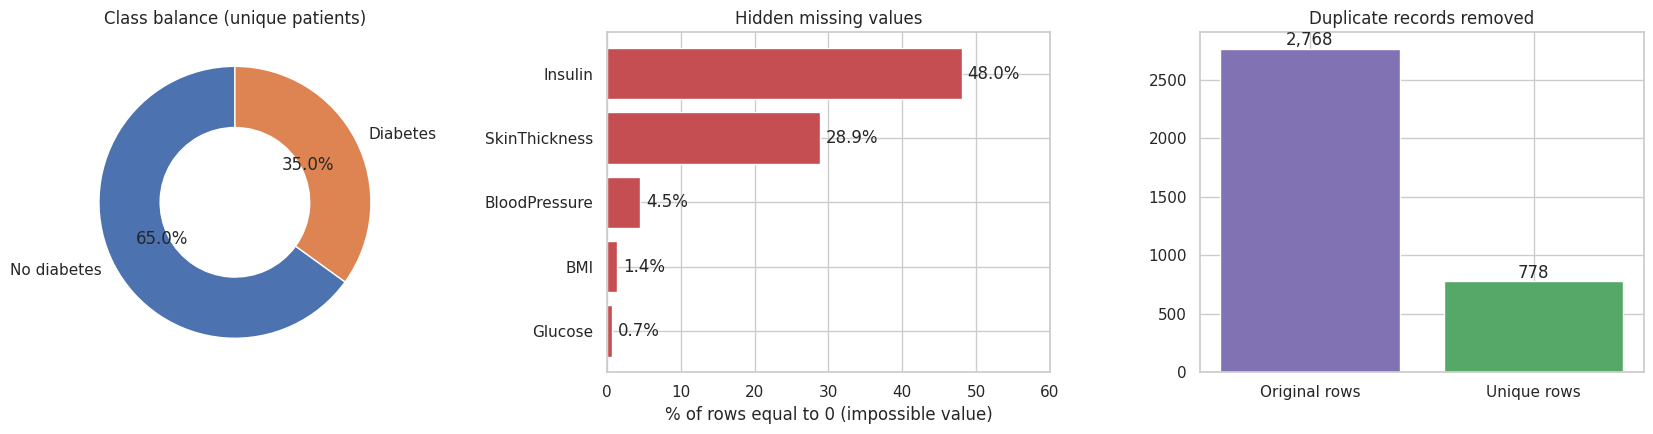

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

counts = clean.Outcome.value_counts().sort_index()
ax[0].pie(counts, labels=["No diabetes", "Diabetes"], autopct="%1.1f%%", colors=[PALETTE[0], PALETTE[1]],
          startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"))
ax[0].set_title("Class balance (unique patients)")

zr = (df[zero_cols] == 0).mean().mul(100).sort_values()
ax[1].barh(zr.index, zr.values, color="#C44E52")
for i, v in enumerate(zr.values): ax[1].text(v + 0.8, i, f"{v:.1f}%", va="center")
ax[1].set_xlabel("% of rows equal to 0 (impossible value)"); ax[1].set_title("Hidden missing values"); ax[1].set_xlim(0, 60)

ax[2].bar(["Original rows", "Unique rows"], [len(df), len(clean)], color=["#8172B3", "#55A868"])
for i, v in enumerate([len(df), len(clean)]): ax[2].text(i, v + 30, f"{v:,}", ha="center")
ax[2].set_title("Duplicate records removed")
plt.tight_layout(); plt.show()

### 6.2 Feature distributions by outcome

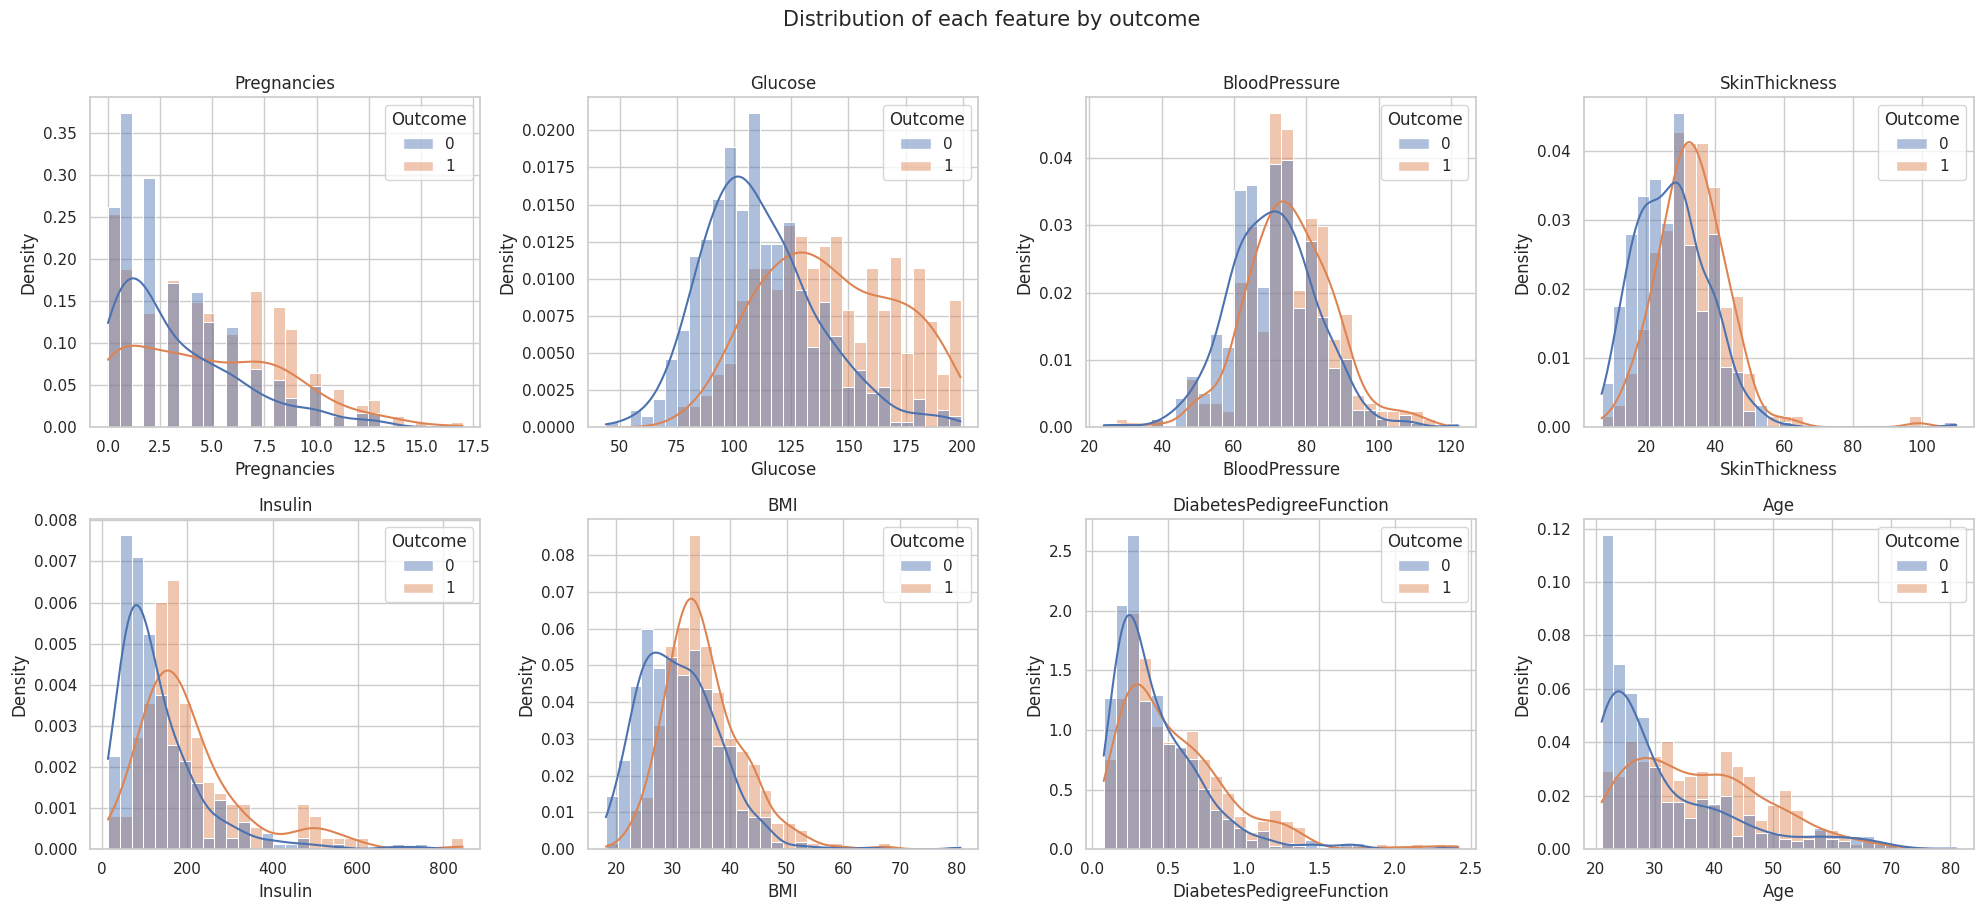

In [26]:
feats = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for a, c in zip(axes.ravel(), feats):
    sns.histplot(data=clean, x=c, hue="Outcome", kde=True, bins=30, palette=PALETTE, stat="density",
                 common_norm=False, alpha=.45, ax=a)
    a.set_title(c)
plt.suptitle("Distribution of each feature by outcome", y=1.01, fontsize=15)
plt.tight_layout(); plt.show()

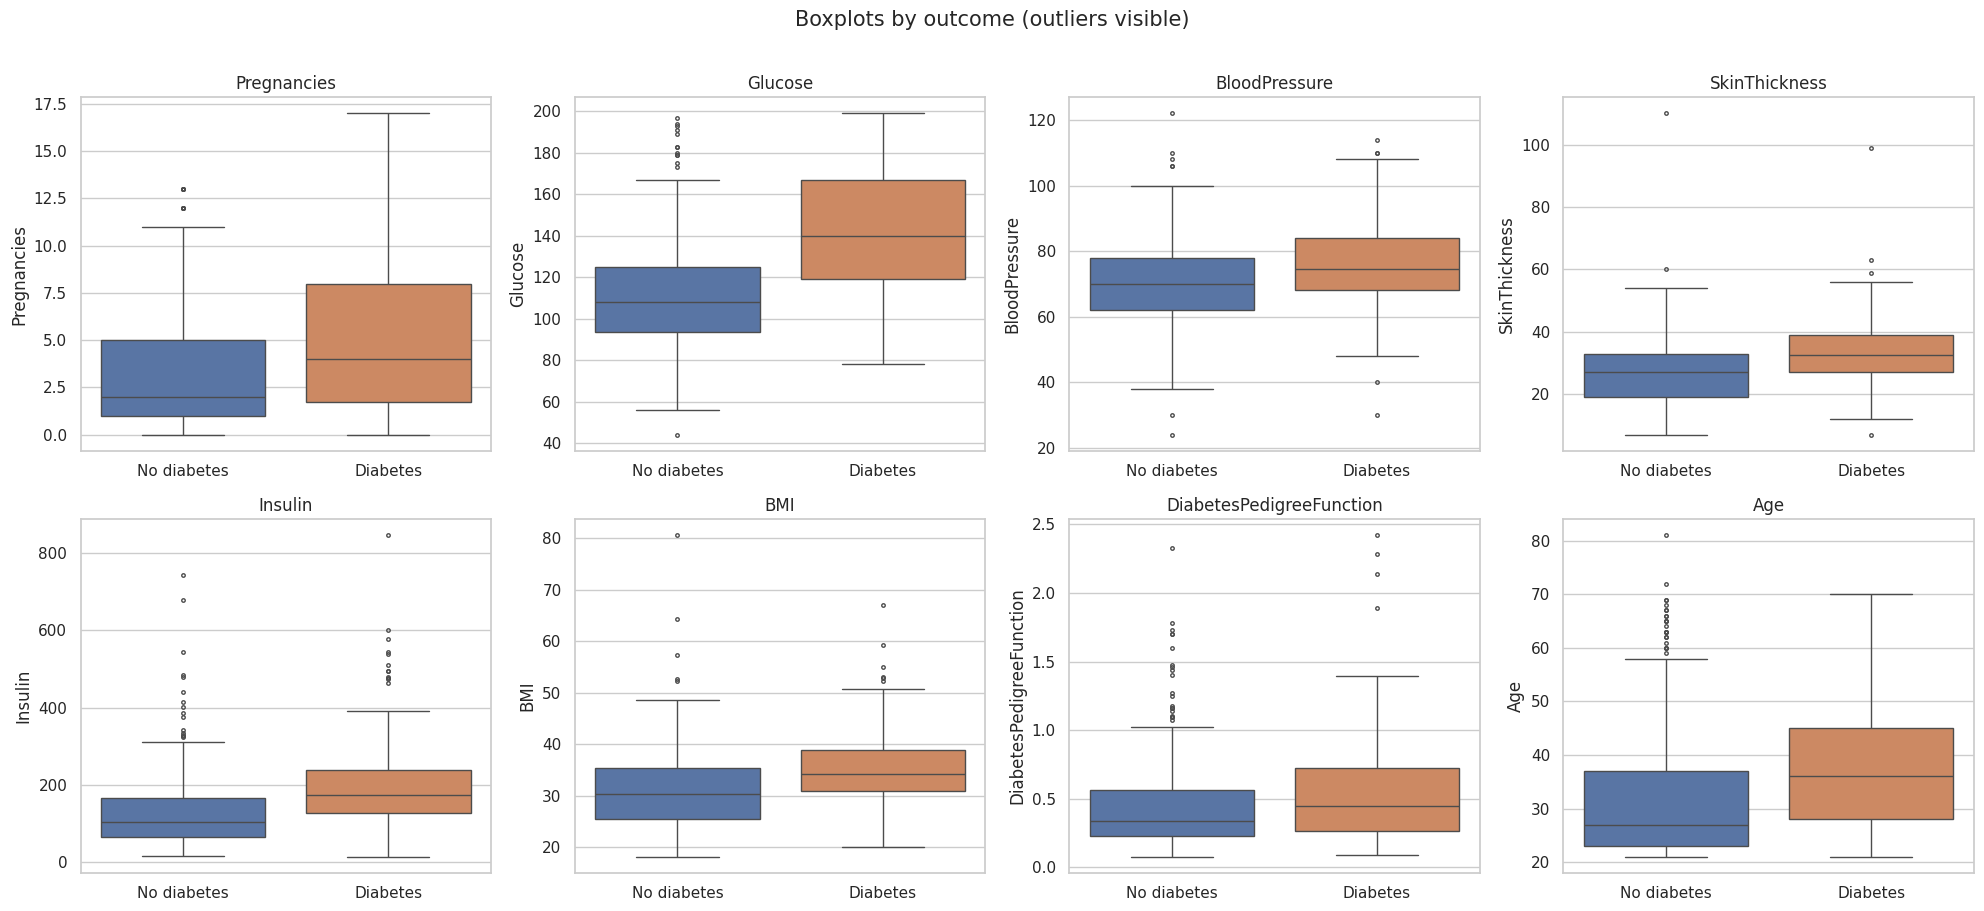

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for a, c in zip(axes.ravel(), feats):
    sns.boxplot(data=clean, x="Outcome", y=c, hue="Outcome", palette=PALETTE, legend=False, ax=a, fliersize=2.5)
    a.set_xticklabels(["No diabetes", "Diabetes"]); a.set_xlabel("")
    a.set_title(c)
plt.suptitle("Boxplots by outcome (outliers visible)", y=1.01, fontsize=15)
plt.tight_layout(); plt.show()

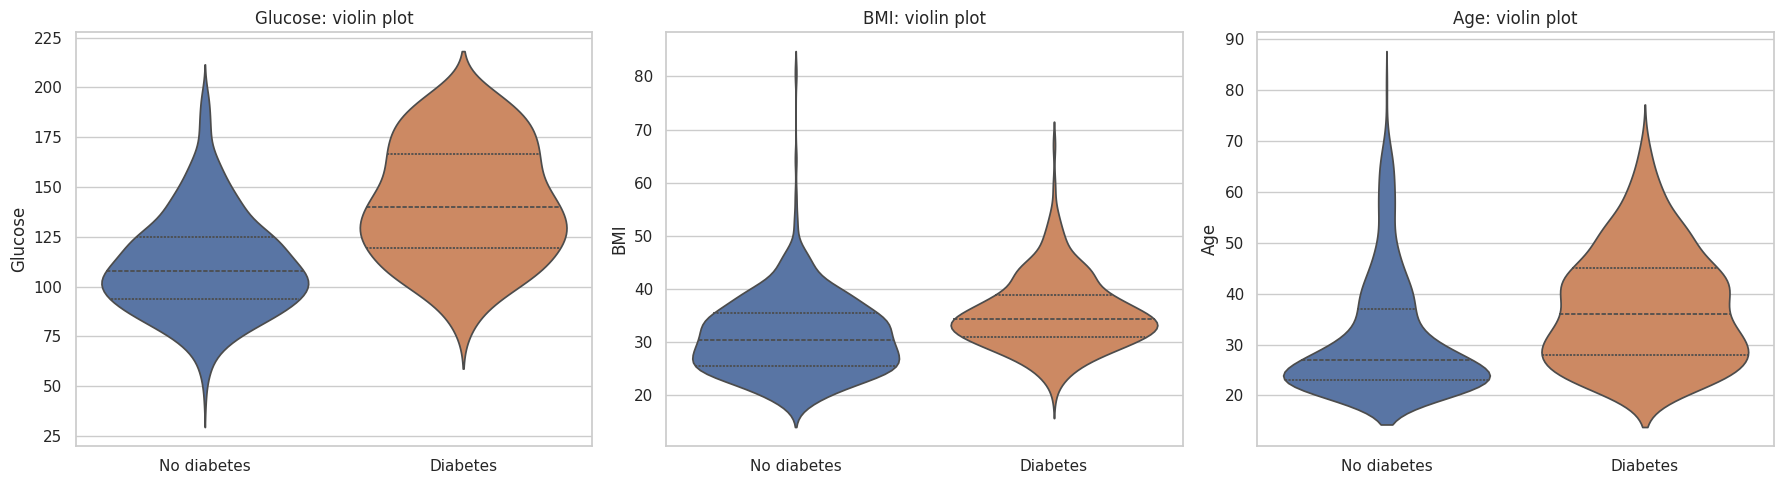

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for a, c in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.violinplot(data=clean, x="Outcome", y=c, hue="Outcome", palette=PALETTE, legend=False, inner="quartile", ax=a)
    a.set_xticklabels(["No diabetes", "Diabetes"]); a.set_xlabel(""); a.set_title(f"{c}: violin plot")
plt.tight_layout(); plt.show()

### 6.3 Relationships between features

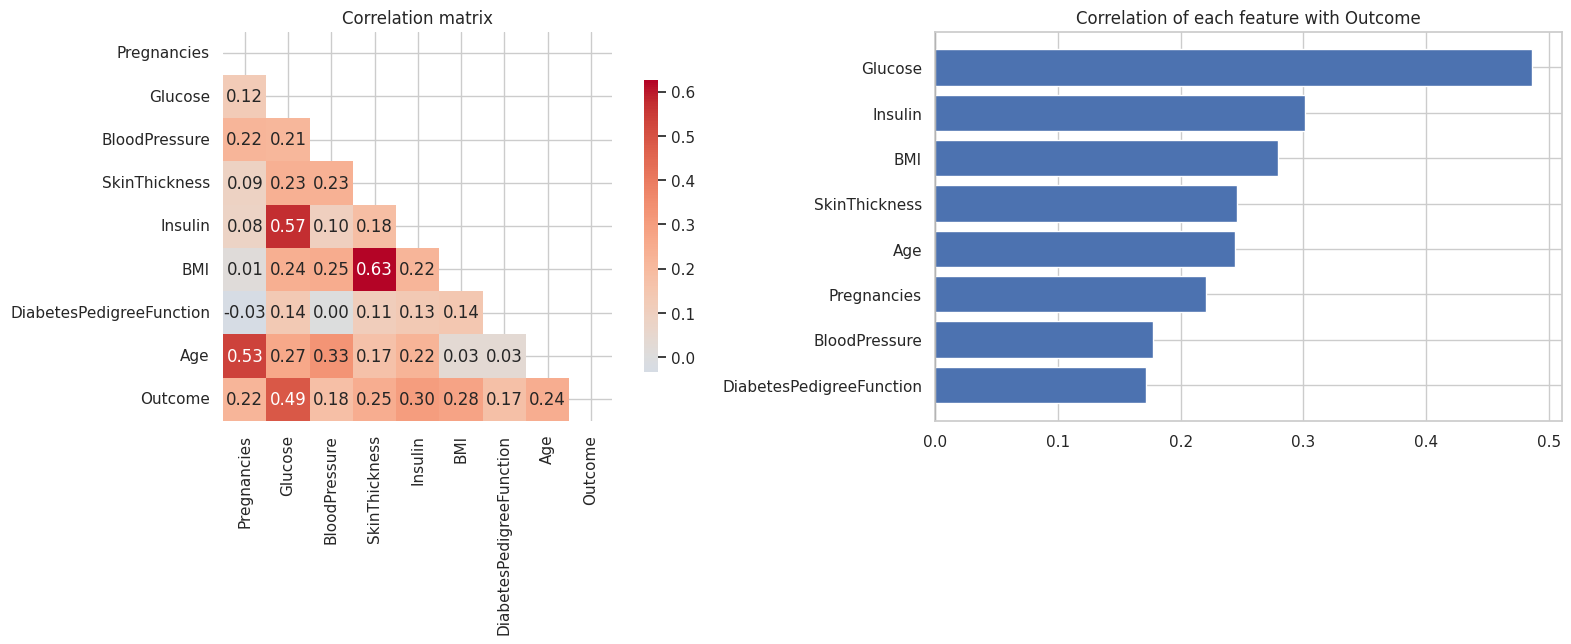

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
corr = clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": .75}, ax=ax[0])
ax[0].set_title("Correlation matrix")

oc = corr["Outcome"].drop("Outcome").sort_values()
ax[1].barh(oc.index, oc.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in oc.values])
ax[1].set_title("Correlation of each feature with Outcome"); ax[1].axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

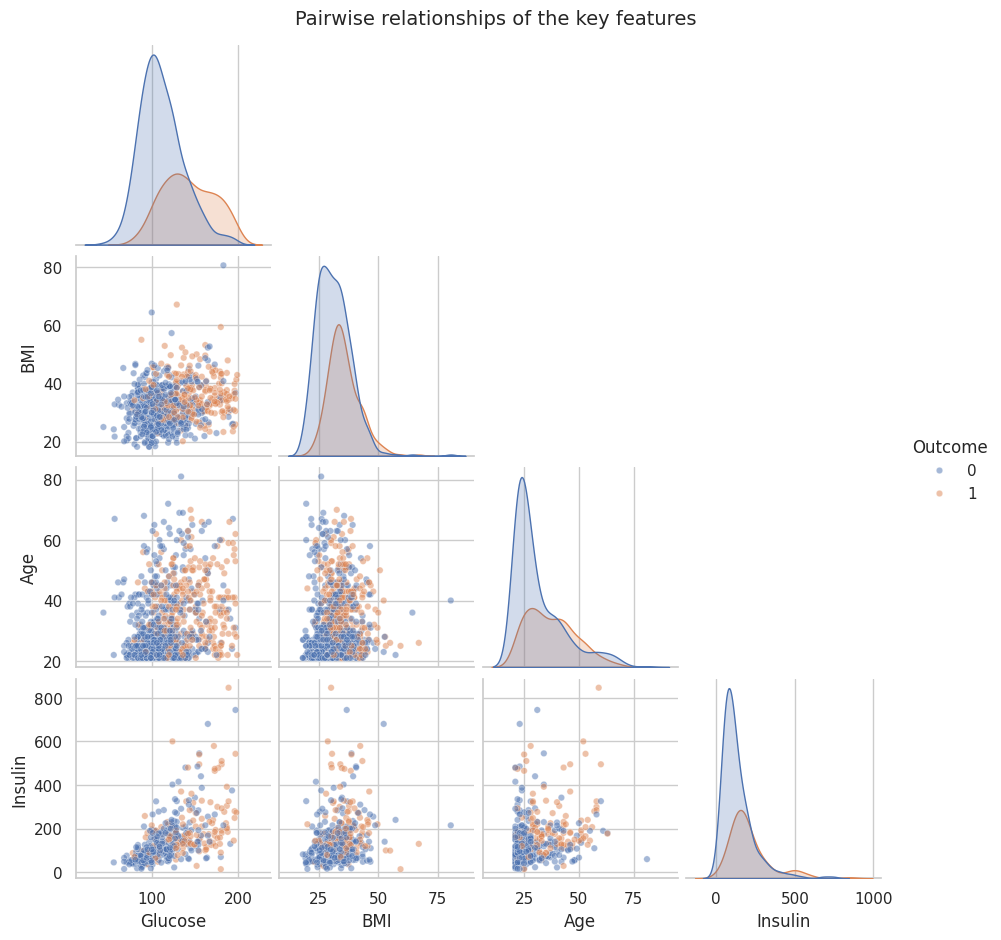

In [30]:
sns.pairplot(clean[["Glucose", "BMI", "Age", "Insulin", "Outcome"]], hue="Outcome", palette=PALETTE,
             corner=True, plot_kws=dict(alpha=.5, s=22), height=2.3)
plt.suptitle("Pairwise relationships of the key features", y=1.02, fontsize=14); plt.show()

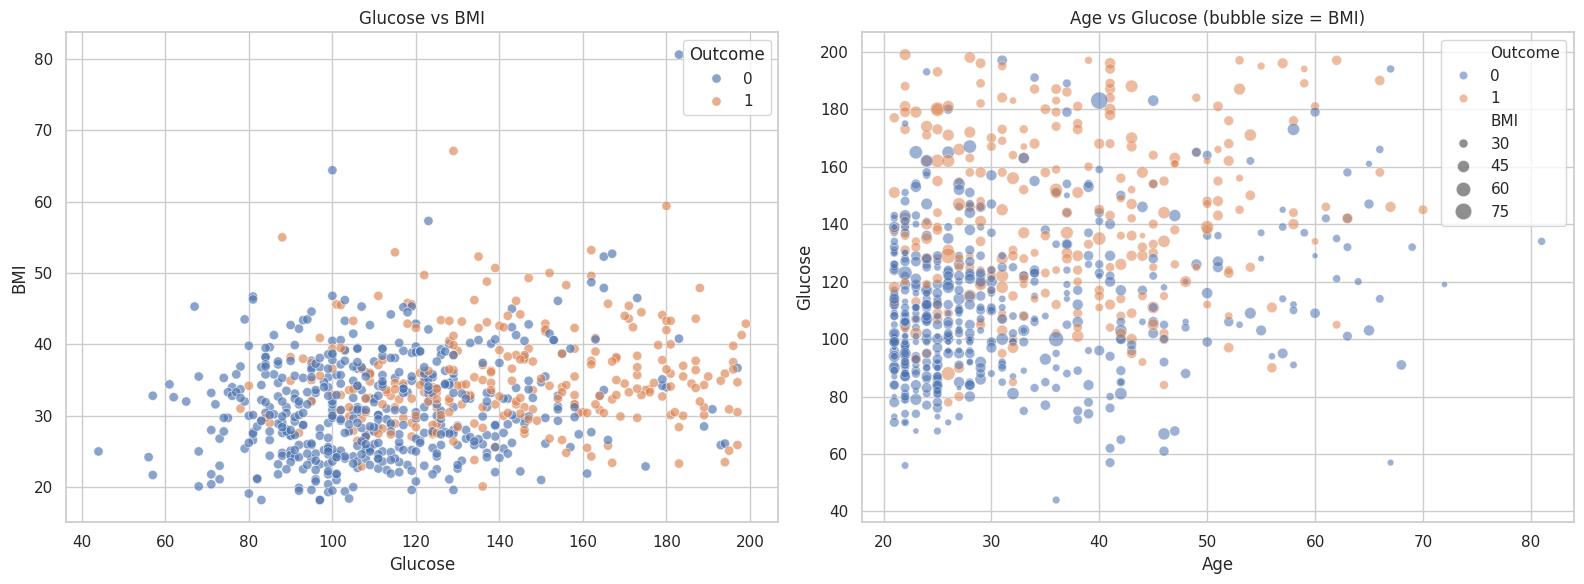

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=clean, x="Glucose", y="BMI", hue="Outcome", palette=PALETTE, alpha=.65, s=45, ax=ax[0])
ax[0].set_title("Glucose vs BMI")
sns.scatterplot(data=clean, x="Age", y="Glucose", hue="Outcome", size="BMI", sizes=(15, 150),
                palette=PALETTE, alpha=.55, ax=ax[1])
ax[1].set_title("Age vs Glucose (bubble size = BMI)")
plt.tight_layout(); plt.show()

### 6.4 Risk by group

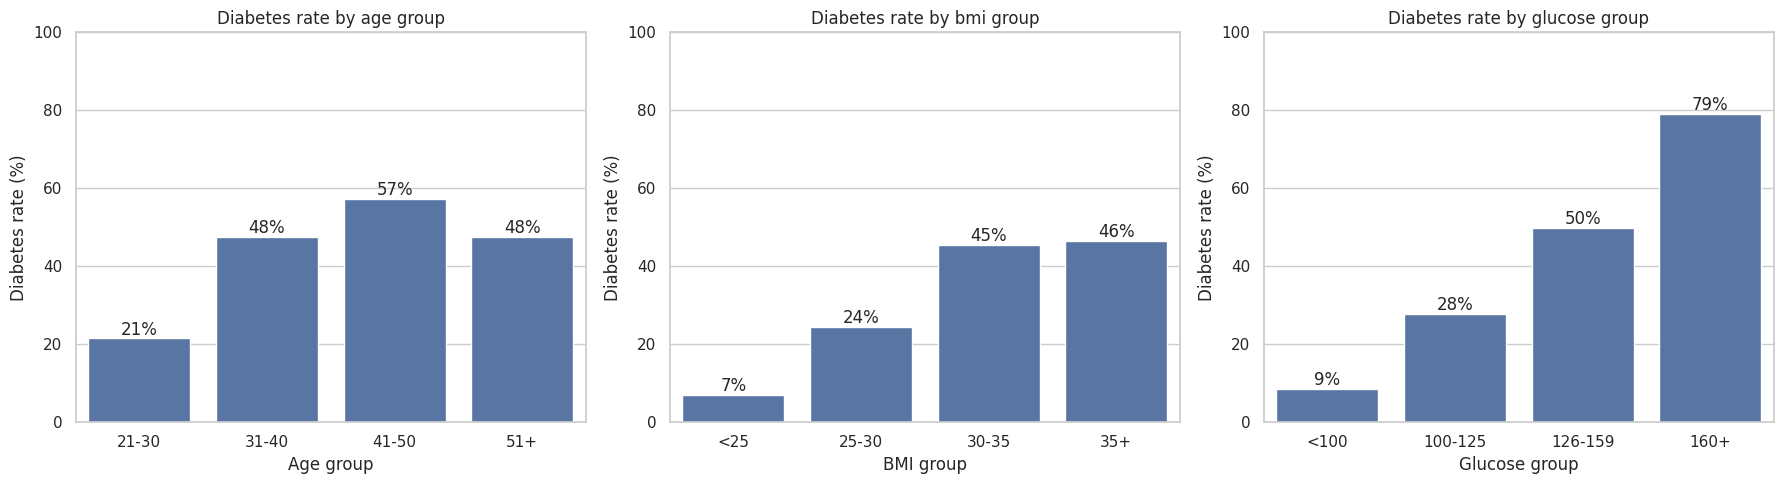

In [32]:
v = clean.copy()
v["Age group"] = pd.cut(v.Age, [20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
v["BMI group"] = pd.cut(v.BMI, [0, 25, 30, 35, 100], labels=["<25", "25-30", "30-35", "35+"])
v["Glucose group"] = pd.cut(v.Glucose, [0, 100, 126, 160, 300], labels=["<100", "100-125", "126-159", "160+"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for a, c in zip(axes, ["Age group", "BMI group", "Glucose group"]):
    r = v.groupby(c, observed=True).Outcome.mean().mul(100)
    sns.barplot(x=r.index, y=r.values, color="#4C72B0", ax=a)
    for i, val in enumerate(r.values): a.text(i, val + 1, f"{val:.0f}%", ha="center")
    a.set_ylabel("Diabetes rate (%)"); a.set_title(f"Diabetes rate by {c.lower()}"); a.set_ylim(0, 100)
plt.tight_layout(); plt.show()

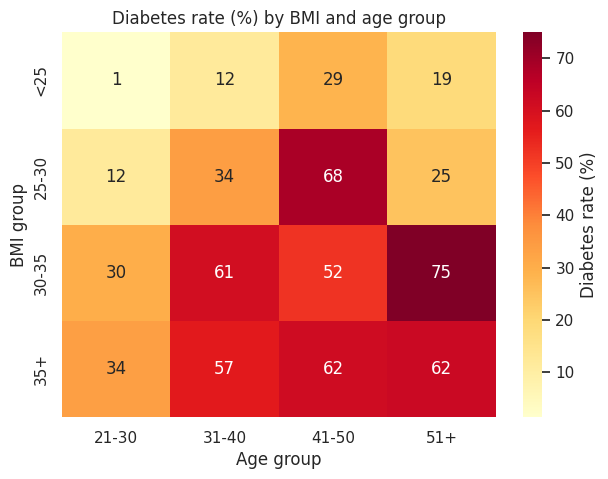

In [33]:
pivot = v.pivot_table(index="BMI group", columns="Age group", values="Outcome", aggfunc="mean", observed=True) * 100
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Diabetes rate (%)"})
plt.title("Diabetes rate (%) by BMI and age group"); plt.show()

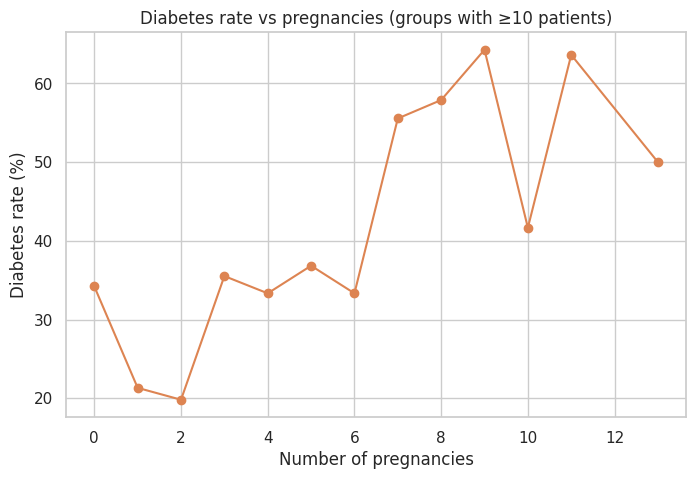

In [34]:
plt.figure(figsize=(8, 5))
r = v.groupby("Pregnancies").Outcome.agg(["mean", "count"])
r = r[r["count"] >= 10]
plt.plot(r.index, r["mean"] * 100, marker="o", color="#DD8452")
plt.xlabel("Number of pregnancies"); plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate vs pregnancies (groups with ≥10 patients)"); plt.show()

## 7. Model Training

### 7a. Baseline comparison (5×3 repeated stratified CV; scoring = ROC-AUC)

Logistic Regression    CV ROC-AUC = 0.8269 ± 0.0345
KNN                    CV ROC-AUC = 0.8107 ± 0.0376
SVM (RBF)              CV ROC-AUC = 0.8186 ± 0.0382
Random Forest          CV ROC-AUC = 0.8116 ± 0.0367
Gradient Boosting      CV ROC-AUC = 0.8113 ± 0.0383


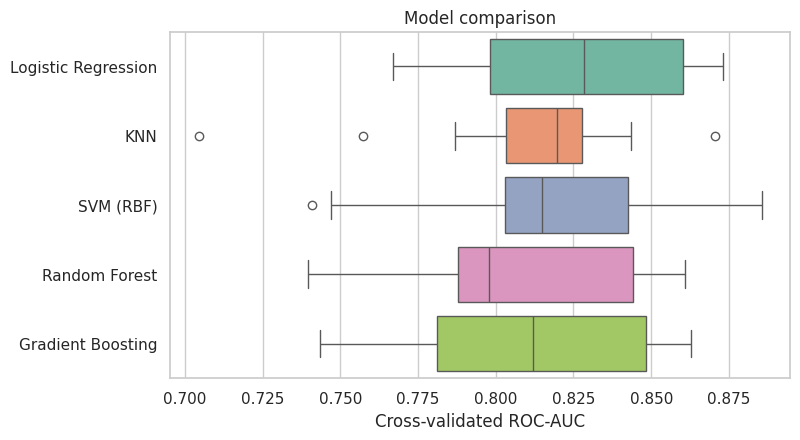

In [35]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
    "Random Forest":       RandomForestClassifier(300, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_res[name] = s
    print(f"{name:22s} CV ROC-AUC = {s.mean():.4f} ± {s.std():.4f}")

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=pd.DataFrame(cv_res), orient="h", palette="Set2")
plt.xlabel("Cross-validated ROC-AUC"); plt.title("Model comparison"); plt.show()

### 7b. Hyperparameter tuning

In [36]:
cv_tune = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

lr_gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=cv_tune, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

rf_gs = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [200, 400], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5]},
    cv=cv_tune, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

gb_gs = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators": [100, 200], "learning_rate": [0.03, 0.1], "max_depth": [2, 3, 4], "subsample": [0.8, 1.0]},
    cv=cv_tune, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

for n, g in [("LR", lr_gs), ("RF", rf_gs), ("GB", gb_gs)]:
    print(f"{n} best: {g.best_params_}  CV AUC = {g.best_score_:.4f}")

LR best: {'logisticregression__C': 0.01}  CV AUC = 0.8346
RF best: {'max_depth': 4, 'min_samples_leaf': 3, 'n_estimators': 400}  CV AUC = 0.8348
GB best: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}  CV AUC = 0.8291


In [37]:
final = {
    "Logistic Regression (tuned)":   lr_gs.best_estimator_,
    "SVM (RBF)":                     models["SVM (RBF)"].fit(X_train, y_train),
    "Random Forest (tuned)":         rf_gs.best_estimator_,
    "Gradient Boosting (tuned)":     gb_gs.best_estimator_,
}

## 8. Model Evaluation (held-out test set)

In [38]:
rows = []
for name, m in final.items():
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    rows.append(dict(Model=name, Accuracy=accuracy_score(y_test, pred), Precision=precision_score(y_test, pred),
                     Recall=recall_score(y_test, pred), F1=f1_score(y_test, pred),
                     ROC_AUC=roc_auc_score(y_test, proba), PR_AUC=average_precision_score(y_test, proba)))
res = pd.DataFrame(rows).set_index("Model").round(4).sort_values("ROC_AUC", ascending=False)
res

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Random Forest (tuned),0.7244,0.6200,0.5636,0.5905,0.8270,0.7162
Gradient Boosting (tuned),0.7115,0.6042,0.5273,0.5631,0.8254,0.7160
Logistic Regression (tuned),0.7308,0.6444,0.5273,0.5800,0.8225,0.6627
SVM (RBF),0.7179,0.6078,0.5636,0.5849,0.8213,0.7147


In [39]:
best_name = res.index[0]; best = final[best_name]
print("Best model by ROC-AUC:", best_name, "\n")
print(classification_report(y_test, best.predict(X_test), target_names=["No diabetes", "Diabetes"]))

Best model by ROC-AUC: Random Forest (tuned) 

              precision    recall  f1-score   support

 No diabetes       0.77      0.81      0.79       101
    Diabetes       0.62      0.56      0.59        55

    accuracy                           0.72       156
   macro avg       0.70      0.69      0.69       156
weighted avg       0.72      0.72      0.72       156



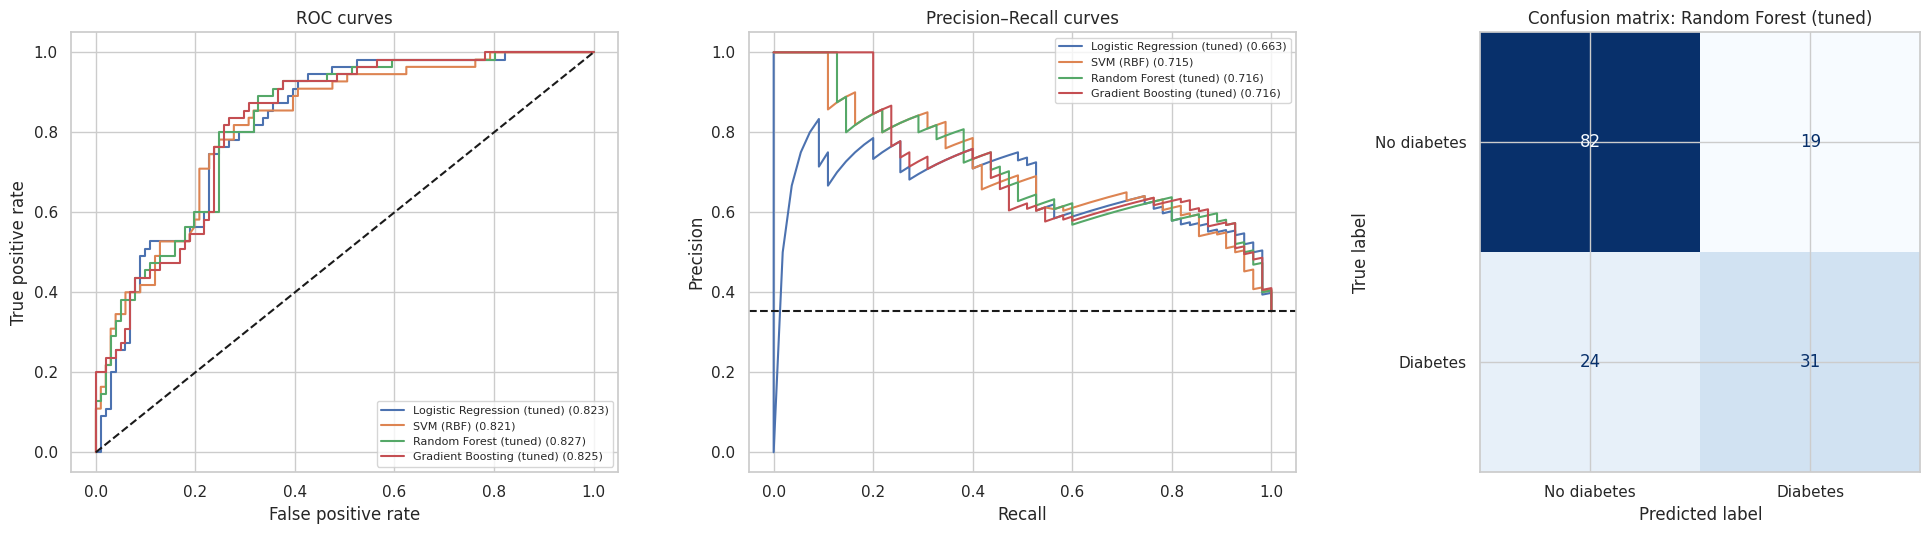

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for name, m in final.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
ax[1].axhline(y_test.mean(), color="k", ls="--"); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curves")
ax[0].legend(loc="lower right", fontsize=8); ax[1].legend(loc="upper right", fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y_test, best.predict(X_test)),
                       display_labels=["No diabetes", "Diabetes"]).plot(ax=ax[2], cmap="Blues", colorbar=False)
ax[2].set_title(f"Confusion matrix: {best_name}")
plt.tight_layout(); plt.show()

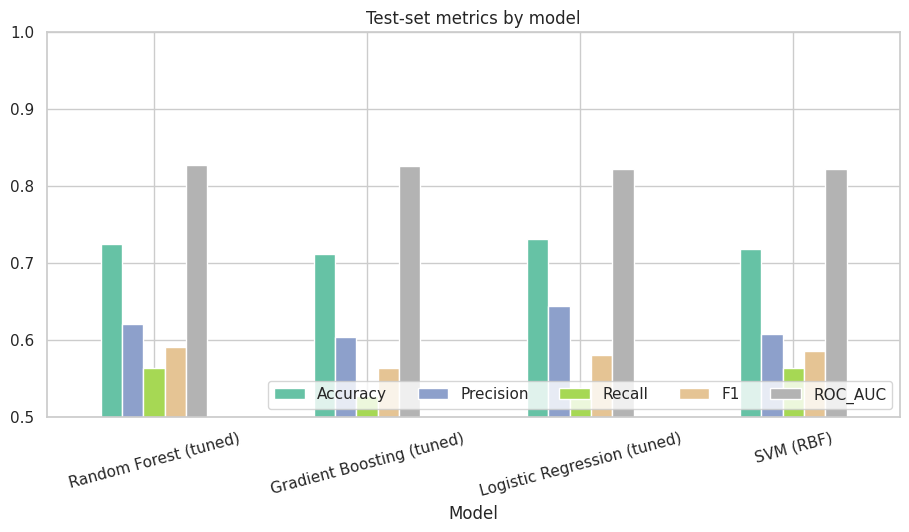

In [41]:
# Metrics side by side
res[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].plot(kind="bar", figsize=(11, 5), colormap="Set2", rot=15)
plt.ylim(0.5, 1); plt.title("Test-set metrics by model"); plt.legend(loc="lower right", ncol=5); plt.show()

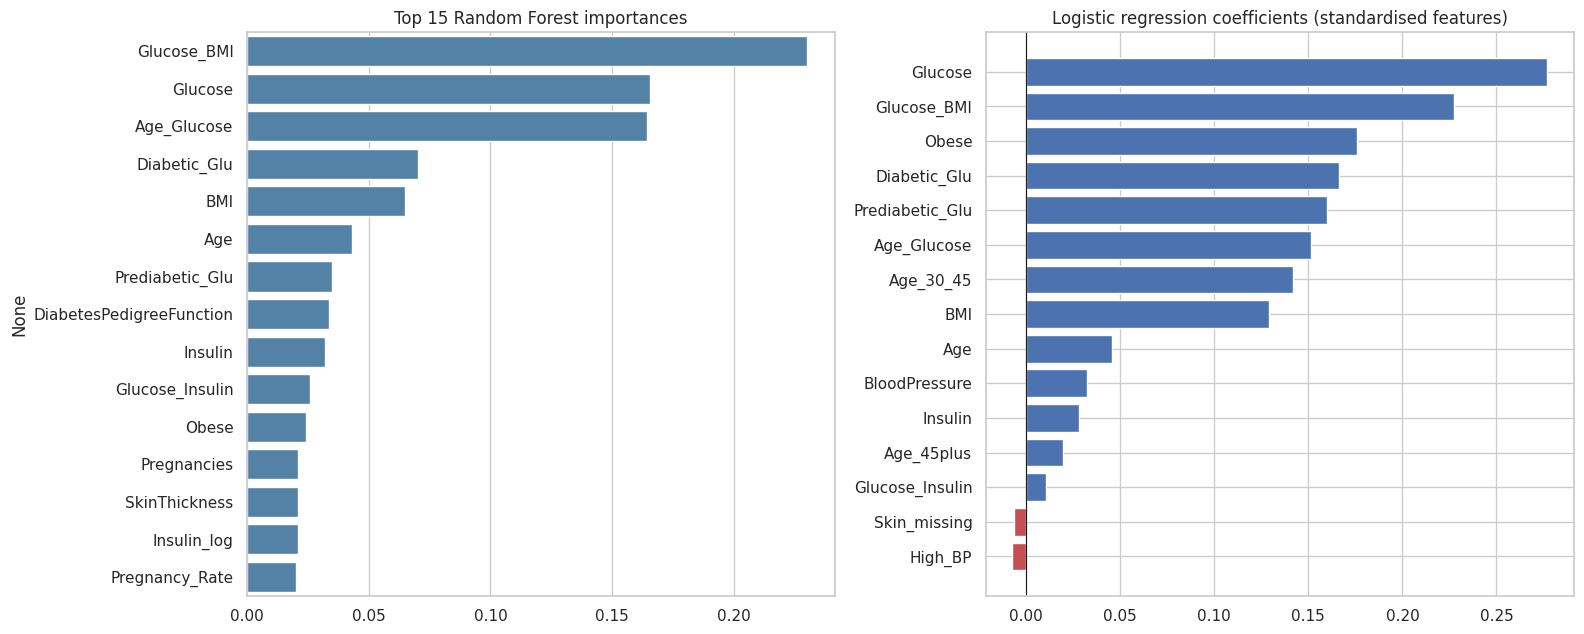

In [42]:
# Feature importance (Random Forest) and logistic-regression coefficients
rf = final["Random Forest (tuned)"]
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

lr = final["Logistic Regression (tuned)"].named_steps["logisticregression"]
coef = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()
coef = pd.concat([coef.head(7), coef.tail(8)])

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
sns.barplot(x=imp.values, y=imp.index, color="steelblue", ax=ax[0]); ax[0].set_title("Top 15 Random Forest importances")
ax[1].barh(coef.index, coef.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in coef.values])
ax[1].axvline(0, color="k", lw=.8); ax[1].set_title("Logistic regression coefficients (standardised features)")
plt.tight_layout(); plt.show()

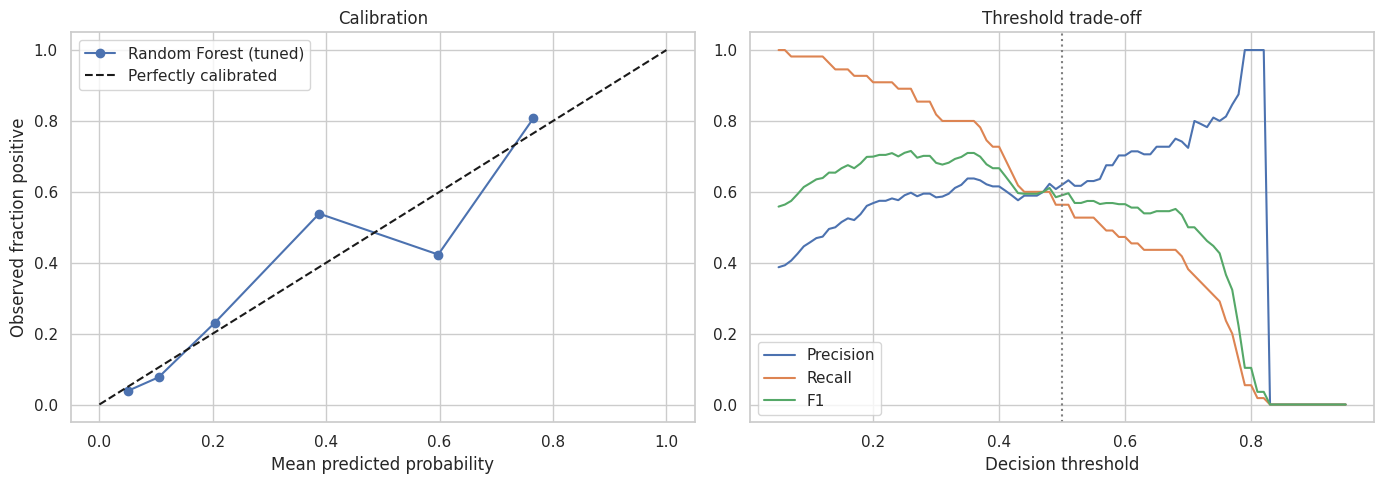

In [43]:
# Calibration and decision-threshold trade-off for the best model
p = best.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

fr, mp = calibration_curve(y_test, p, n_bins=6, strategy="quantile")
ax[0].plot(mp, fr, marker="o", label=best_name); ax[0].plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax[0].set(xlabel="Mean predicted probability", ylabel="Observed fraction positive", title="Calibration"); ax[0].legend()

ths = np.linspace(0.05, 0.95, 91)
ax[1].plot(ths, [precision_score(y_test, p >= t, zero_division=0) for t in ths], label="Precision")
ax[1].plot(ths, [recall_score(y_test, p >= t) for t in ths], label="Recall")
ax[1].plot(ths, [f1_score(y_test, p >= t) for t in ths], label="F1")
ax[1].axvline(0.5, color="gray", ls=":"); ax[1].set(xlabel="Decision threshold", title="Threshold trade-off"); ax[1].legend()
plt.tight_layout(); plt.show()

## Conclusions
- **Data quality dominates this dataset.** ~72% of the rows are exact duplicates (ignoring `Id`), and many 0s are really missing values. Leaving duplicates in inflates test accuracy (see the demonstration in section 2) because the same patient appears in both train and test.
- After cleaning, all models reach roughly **ROC-AUC 0.82–0.83 and ~71–73% test accuracy** — realistic for this classic dataset, and far below the ~99% a leaky split would suggest.
- **Glucose** is the dominant predictor, followed by BMI, age and engineered interactions (`Glucose_BMI`, `Age_Glucose`).
- Recall for the diabetic class is lower than for the non-diabetic class; for screening use, lowering the decision threshold (see the threshold plot) would catch more true cases at the cost of more false alarms.
- With only ~780 unique patients, the test set is small, so differences of a couple of points between models are not statistically meaningful.